In [1]:
! pip install matplotlib

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt


In [3]:
import os
print("Current Working Directory:", os.getcwd())

Current Working Directory: c:\Users\amjat\Pictures\AICW 2.0\plant_leaf_disease_detection


In [ ]:
current_directory=os.getcwd()
train_path=os.path.join(current_directory,'Data','Training') #copy the path respectively for your training data folder
valid_path=os.path.join(current_directory,'Data','Validation')
test_path=os.path.join(current_directory,'Data','Testing')

In [5]:
train_path

'c:\\Users\\amjat\\Pictures\\AICW 2.0\\plant_leaf_disease_detection\\Data\\Training'

In [6]:
valid_path

'c:\\Users\\amjat\\Pictures\\AICW 2.0\\plant_leaf_disease_detection\\Data\\Validation'

In [7]:
test_path

'c:\\Users\\amjat\\Pictures\\AICW 2.0\\plant_leaf_disease_detection\\Data\\Testing'

In [8]:
#function is uused to cretae an image dataset from the directory structure where images are organijsed in subfolders based on their class labels. It reads the images from the specified directory, resizes them to the target size, and splits them into batches for training or validation. The function also allows for shuffling the data and specifying a random seed for reproducibility.
training_set=tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear",  #it will resize the images to the target size using bilinear interpolation 
)

#so the training_set variable will contain a dataset of images and their corresponding labels, ready to be used for training a machine learning model. The images will be resized to 128x128 pixels, and the labels will be one-hot encoded for multi-class classification.
#so these are parameters that are used to create an image dataset from a directory of images for training a machine learning model. The parameters specify how the images should be processed and organized into batches for training.

Found 3251 files belonging to 3 classes.


In [9]:
validation_set=tf.keras.utils.image_dataset_from_directory(
    valid_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear",  #it will resize the images to the target size using bilinear interpolation 
)


Found 416 files belonging to 3 classes.


In [10]:
testing_set=tf.keras.utils.image_dataset_from_directory(
    test_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear",  #it will resize the images to the target size using bilinear interpolation 
)


Found 405 files belonging to 3 classes.


In [11]:
cnn = tf.keras.models.Sequential()

cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(units=1500,activation='relu'))
cnn.add(tf.keras.layers.Dropout(0.4))

cnn.add(tf.keras.layers.Dense(units=3,activation='softmax'))

c:\Users\amjat\Pictures\AICW 2.0\plant_leaf_disease_detection\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [14]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         4,503 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,790,227 (29.72 MB)

 Trainable params: 7,790,227 (29.72 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
training_history=cnn.fit(x=training_set,validation_data=validation_set,epochs=10)

Epoch 1/10


c:\Users\amjat\Pictures\AICW 2.0\plant_leaf_disease_detection\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


102/102 ━━━━━━━━━━━━━━━━━━━━ 178s 2s/step - accuracy: 0.5140 - loss: 1.0288 - val_accuracy: 0.6466 - val_loss: 0.8407
Epoch 2/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 166s 2s/step - accuracy: 0.6936 - loss: 0.7274 - val_accuracy: 0.7837 - val_loss: 0.5542
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 155s 2s/step - accuracy: 0.7982 - loss: 0.5098 - val_accuracy: 0.8534 - val_loss: 0.3902
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 272s 3s/step - accuracy: 0.8640 - loss: 0.3694 - val_accuracy: 0.8365 - val_loss: 0.4206
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 149s 1s/step - accuracy: 0.8970 - loss: 0.2873 - val_accuracy: 0.9255 - val_loss: 0.2190
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step - accuracy: 0.9246 - loss: 0.2209 - val_accuracy: 0.9231 - val_loss: 0.2464
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 152s 1s/step - accuracy: 0.9419 - loss: 0.1614 - val_accuracy: 0.9183 - val_loss: 0.2509
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 149s 1s/step - accuracy: 0.9382 - loss: 0.1619 - val_accuracy: 0.918

In [16]:
cnn.save('trained_plant_disease_model.keras')

In [17]:
training_history.history

{'accuracy': [0.5139957070350647,
  0.6936327219009399,
  0.798215925693512,
  0.864041805267334,
  0.8969547748565674,
  0.924638569355011,
  0.941864013671875,
  0.9381728768348694,
  0.9520147442817688,
  0.9670870304107666],
 'loss': [1.0288141965866089,
  0.72743821144104,
  0.5098320841789246,
  0.36943212151527405,
  0.2873140871524811,
  0.22091957926750183,
  0.1614469587802887,
  0.1618630588054657,
  0.13860581815242767,
  0.1018223837018013],
 'val_accuracy': [0.6466346383094788,
  0.7836538553237915,
  0.8533653616905212,
  0.8365384340286255,
  0.9254807829856873,
  0.9230769276618958,
  0.9182692170143127,
  0.9182692170143127,
  0.9278846383094788,
  0.9495192170143127],
 'val_loss': [0.8406838774681091,
  0.5542227625846863,
  0.3901882767677307,
  0.4206386208534241,
  0.2190062403678894,
  0.2464311718940735,
  0.25088268518447876,
  0.20511150360107422,
  0.157540425658226,
  0.18028846383094788]}

<function matplotlib.pyplot.show(close=None, block=None)>

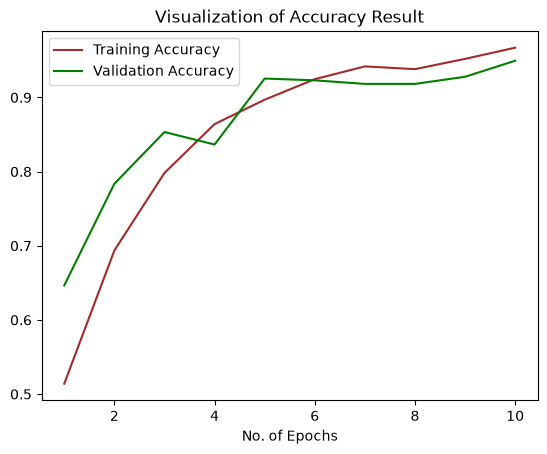

In [19]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='brown',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='green',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show